# 🌍 Analisis Eksplorasi Awal: CO2 Emissions Dataset

Notebook ini memuat inspeksi awal dataset **CO2 Emissions** yang diunduh langsung dari Kaggle menggunakan pustaka `kagglehub` (`saloni1712/co2-emissions`).

### 🎯 Tujuan Eksplorasi:
1. Mengunduh dan memuat dataset emisi $\text{CO}_2$ secara otomatis via `kagglehub`.
2. Memeriksa **dimensi data** (jumlah baris dan kolom).
3. Memeriksa **daftar kolom** dan tipe datanya.
4. Memeriksa keberadaan **missing value** (nilai kosong/hilang).
5. Menganalisis ringkasan statistik dan sebaran nilai unik fitur kunci.

In [1]:
import os
import kagglehub
import pandas as pd
import numpy as np

# 1. Download latest version dataset dari Kaggle via kagglehub
path = kagglehub.dataset_download("saloni1712/co2-emissions")
print("Path to dataset files:", path)

# Periksa berkas yang tersedia di direktori dataset
files = os.listdir(path)
print("Berkas dalam direktori:", files)

Path to dataset files: C:\Users\MyBook Z Series\.cache\kagglehub\datasets\saloni1712\co2-emissions\versions\1
Berkas dalam direktori: ['dataset.csv']


---
## 📊 1. Memuat Data & Memeriksa Dimensi Dataset

In [2]:
# Membaca dataset CSV ke DataFrame Pandas
csv_file = os.path.join(path, "dataset.csv")
df = pd.read_csv(csv_file)

# Memeriksa dimensi dataset (shape)
n_rows, n_cols = df.shape
print("=" * 50)
print("DIMENSI DATASET:")
print(f"• Jumlah Baris (Sampel Observasi) : {n_rows:,}")
print(f"• Jumlah Kolom (Fitur / Variabel) : {n_cols}")
print("=" * 50)

# Menampilkan 5 baris pertama data
df.head()

DIMENSI DATASET:
• Jumlah Baris (Sampel Observasi) : 135,408
• Jumlah Kolom (Fitur / Variabel) : 5


,country,date,sector,value,timestamp
0,Brazil,01/01/2019,Power,0.096799,1546300800
1,China,01/01/2019,Power,14.816100,1546300800
2,EU27 & UK,01/01/2019,Power,1.886490,1546300800
3,France,01/01/2019,Power,0.051217,1546300800
4,Germany,01/01/2019,Power,0.315002,1546300800


---
## 📋 2. Memeriksa Daftar Kolom dan Tipe Data

In [3]:
# Menampilkan daftar kolom dan tipe data masing-masing
print("=" * 50)
print("DAFTAR KOLOM DAN TIPE DATA:")
print("=" * 50)
for idx, (col, dtype) in enumerate(zip(df.columns, df.dtypes), 1):
    print(f"{idx}. Kolom '{col:<12}' -> Tipe: {dtype}")

print("\nRingkasan Struktur DataFrame:")
df.info()

DAFTAR KOLOM DAN TIPE DATA:
1. Kolom 'country     ' -> Tipe: str
2. Kolom 'date        ' -> Tipe: str
3. Kolom 'sector      ' -> Tipe: str
4. Kolom 'value       ' -> Tipe: float64
5. Kolom 'timestamp   ' -> Tipe: int64

Ringkasan Struktur DataFrame:
<class 'pandas.DataFrame'>
RangeIndex: 135408 entries, 0 to 135407
Data columns (total 5 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   country    135408 non-null  str    
 1   date       135408 non-null  str    
 2   sector     135408 non-null  str    
 3   value      135408 non-null  float64
 4   timestamp  135408 non-null  int64  
dtypes: float64(1), int64(1), str(3)
memory usage: 5.2 MB


---
## 🔍 3. Pemeriksaan Missing Value (Nilai Hilang)

In [4]:
# Menghitung jumlah dan persentase missing value per kolom
missing_count = df.isnull().sum()
missing_percent = (missing_count / len(df)) * 100

df_missing = pd.DataFrame({
    "Kolom": df.columns,
    "Tipe Data": df.dtypes.values,
    "Jumlah Missing": missing_count.values,
    "Persentase (%)": missing_percent.values
})

print("=" * 60)
print("HASIL PEMERIKSAAN MISSING VALUE:")
print("=" * 60)
print(df_missing.to_string(index=False))

total_missing = df.isnull().sum().sum()
print("-" * 60)
print(f"Total Missing Value di Seluruh Dataset: {total_missing}")
if total_missing == 0:
    print("✅ STATUS: Dataset 100% BERSIH, tidak ditemukan missing value (nilai kosong).")
else:
    print("⚠️ STATUS: Ditemukan nilai yang hilang pada beberapa kolom.")
print("=" * 60)

HASIL PEMERIKSAAN MISSING VALUE:
    Kolom Tipe Data  Jumlah Missing  Persentase (%)
  country       str               0             0.0
     date       str               0             0.0
   sector       str               0             0.0
    value   float64               0             0.0
timestamp     int64               0             0.0


------------------------------------------------------------
Total Missing Value di Seluruh Dataset: 0
✅ STATUS: Dataset 100% BERSIH, tidak ditemukan missing value (nilai kosong).


---
## 📈 4. Eksplorasi Nilai Unik dan Karakteristik Fitur Kunci

In [5]:
# Nilai unik untuk kolom kategorikal
print("=" * 60)
print(f"1. Kolom 'country' ({df['country'].nunique()} entitas):")
print(df['country'].unique())

print("\n" + "=" * 60)
print(f"2. Kolom 'sector' ({df['sector'].nunique()} sektor industri):")
print(df['sector'].unique())

print("\n" + "=" * 60)
print("3. Rentang Waktu (Kolom 'date'):")
print(f"• Tanggal Minimum : {df['date'].min()}")
print(f"• Tanggal Maksimum : {df['date'].max()}")

print("\n" + "=" * 60)
print("4. Ringkasan Statistik Emisi CO2 (Kolom 'value'):")
print(df['value'].describe())
print("=" * 60)

1. Kolom 'country' (14 entitas):
<StringArray>
[   'Brazil',     'China', 'EU27 & UK',    'France',   'Germany',     'India',
     'Italy',     'Japan',       'ROW',    'Russia',     'Spain',        'UK',
        'US',     'WORLD']
Length: 14, dtype: str

2. Kolom 'sector' (6 sektor industri):
<StringArray>
[                 'Power',               'Industry',       'Ground Transport',
            'Residential',      'Domestic Aviation', 'International Aviation']
Length: 6, dtype: str

3. Rentang Waktu (Kolom 'date'):
• Tanggal Minimum : 01/01/2019
• Tanggal Maksimum : 31/12/2022

4. Ringkasan Statistik Emisi CO2 (Kolom 'value'):
count    135408.000000
mean          2.359439
std           5.908582
min           0.000078
25%           0.078661
50%           0.314597
75%           1.636632
max          46.263500
Name: value, dtype: float64


---
## 📌 Ringkasan Hasil Eksplorasi

| Parameter | Hasil Analisis |
| :--- | :--- |
| **Dimensi Dataset** | **135.408 baris** $\times$ **5 kolom** |
| **Daftar Kolom** | `country`, `date`, `sector`, `value`, `timestamp` |
| **Tipe Data** | `object` (`country`, `date`, `sector`), `float64` (`value`), `int64` (`timestamp`) |
| **Missing Values** | **0 (Nol)** — Tidak ada missing value di seluruh kolom |
| **Cakupan Entitas** | 14 negara/kawasan (termasuk EU27 & UK, ROW, WORLD) |
| **Cakupan Sektor** | 6 sektor: *Power, Industry, Ground Transport, Residential, Domestic Aviation, International Aviation* |
| **Rentang Waktu** | 01 Januari 2019 hingga 31 Desember 2022 |

---
## 📉 5. Visualisasi Emisi CO2 Sektor Residential di US ($x = \text{date}$, $y = \text{value}$)

Pada bagian ini, kita melakukan pemfilteran data khusus untuk:
* **Negara (`country`)**: `US` (Amerika Serikat)
* **Sektor (`sector`)**: `Residential` (Pemukiman/Rumah Tangga)

Kolom `date` dikonversi ke tipe data `datetime` dan diurutkan secara kronologis agar plot deret waktu terbentuk dengan benar.

• Jumlah sampel data US Residential : 1,612 baris
• Rentang observasi                : 01 January 2019 s.d. 31 May 2023


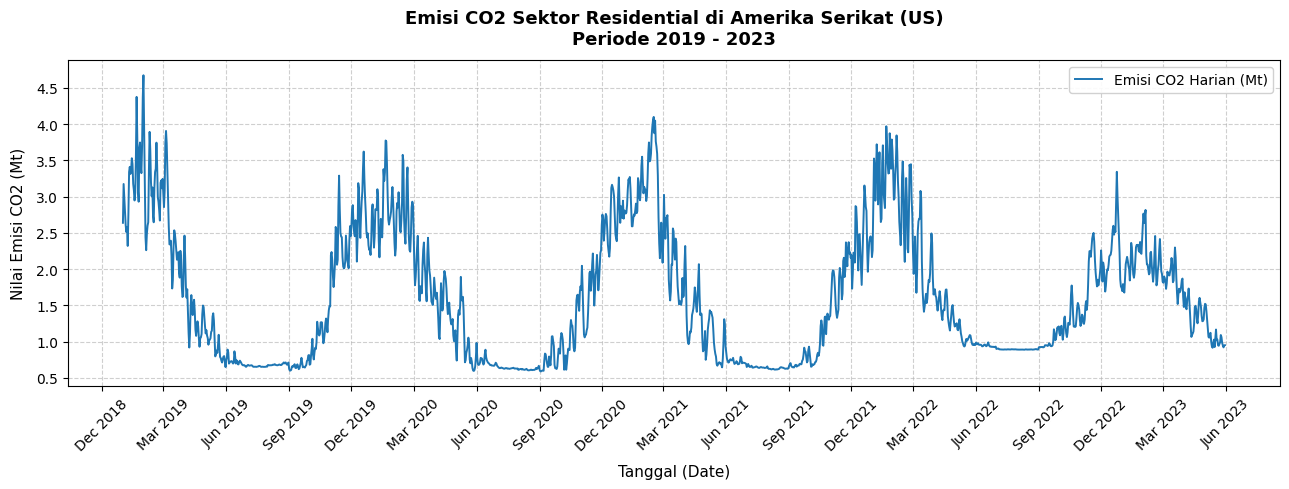

In [6]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# 1. Filter data untuk negara 'US' dan sektor 'Residential'
df_us_res = df[(df['country'] == 'US') & (df['sector'] == 'Residential')].copy()

# 2. Konversi kolom date ke tipe datetime dan urutkan kronologis
df_us_res['date'] = pd.to_datetime(df_us_res['date'], format='%d/%m/%Y')
df_us_res = df_us_res.sort_values('date').reset_index(drop=True)

print(f"• Jumlah sampel data US Residential : {len(df_us_res):,} baris")
print(f"• Rentang observasi                : {df_us_res['date'].min().strftime('%d %B %Y')} s.d. {df_us_res['date'].max().strftime('%d %B %Y')}")

# 3. Membuat visualisasi plot garis sederhana (Date vs Value)
plt.figure(figsize=(13, 5))
plt.plot(df_us_res['date'], df_us_res['value'], color='#1f77b4', linewidth=1.4, label='Emisi CO2 Harian (Mt)')

# Kustomisasi tampilan plot
plt.title('Emisi CO2 Sektor Residential di Amerika Serikat (US)\nPeriode 2019 - 2023', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Tanggal (Date)', fontsize=11, labelpad=8)
plt.ylabel('Nilai Emisi CO2 (Mt)', fontsize=11, labelpad=8)
plt.grid(True, linestyle='--', alpha=0.6)

# Format sumbu X agar rapi per kuartal
plt.gca().xaxis.set_major_locator(mdates.MonthLocator(interval=3))
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
plt.xticks(rotation=45)

plt.legend(loc='upper right', frameon=True, facecolor='white', framealpha=0.9)
plt.tight_layout()
plt.show()

### 💡 Observasi & Karakteristik Deret Waktu:
1. **Pola Musiman yang Sangat Kuat (*Strong Seasonality*)**:
   Grafik di atas memperlihatkan siklus osilasi tahunan yang sangat jelas dan berulang teratur:
   * **Puncak Emisi (Peak)** terjadi di sekitar **Desember - Februari** (musim dingin), karena konsumsi energi tinggi untuk pemanas ruangan (*space heating*).
   * **Titik Terendah (Trough)** terjadi di sekitar **Juni - Agustus** (musim panas).
2. **Relevansi dengan Tugas Akhir (Gaussian Process)**:
   Pola deret waktu musiman seperti ini sangat cocok dimodelkan menggunakan **Gaussian Process Regression (GPR)** dengan kombinasi kernel: perpaduan antara **Kernel Periodik / Exp-Sine-Squared** (untuk menangkap siklus tahunan) dan **Kernel RBF/SE** (untuk menangkap tren jangka panjang dan peluruhan korelasi).

---
# 🔮 6. Eksperimen Gaussian Process Regression (GPR) dengan 4 Kombinasi Kernel Non-RBF

Sesuai dengan arahan eksplorasi, pada bagian ini kita memodelkan data deret waktu emisi $\text{CO}_2$ sektor *Residential US* menggunakan **4 kombinasi berbeda dari 2 kernel tanpa melibatkan kernel RBF** (*Radial Basis Function / Squared Exponential*).

### 📚 Formulasi Matematis Kernel Alternatif yang Digunakan:
1. **`ExpSineSquared` (Kernel Periodik)**:
   $$k_{\text{ESS}}(t, t') = \sigma_p^2 \exp\left(-\frac{2 \sin^2(\pi |t - t'| / p)}{\ell_p^2}\right)$$
   *Fungsi*: Menangkap pola siklis musiman tahunan yang berulang secara eksak dengan periode $p \approx 1.0$ tahun.

2. **`RationalQuadratic` (Kernel Kuadratik Rasional)**:
   $$k_{\text{RQ}}(t, t') = \sigma_{\text{rq}}^2 \left(1 + \frac{(t - t')^2}{2\alpha \ell_{\text{rq}}^2}\right)^{-\alpha}$$
   *Fungsi*: Memodelkan variasi korelasi multi-skala (ekuivalen dengan campuran kontinu tak hingga dari kernel RBF dengan berbagai panjang skala $\ell$).

3. **`DotProduct` (Kernel Linier)**:
   $$k_{\text{Lin}}(t, t') = \sigma_0^2 + t \cdot t'$$
   *Fungsi*: Menangkap tren kenaikan atau penurunan linier global non-stasioner melintasi waktu.

4. **`Matern` (Kernel Matérn, $\nu = 1.5$ dan $\nu = 2.5$)**:
   $$k_{\text{Mat2.5}}(t, t') = \sigma_m^2 \left(1 + \frac{\sqrt{5}|t - t'|}{\ell_m} + \frac{5(t - t')^2}{3\ell_m^2}\right) \exp\left(-\frac{\sqrt{5}|t - t'|}{\ell_m}\right)$$
   *Fungsi*: Menangkap fluktuasi lokal dengan tingkat keterdiferensialan terbatas (lebih realistis untuk proses fisik nyata dibandingkan RBF yang terlalu mulus/$\mathcal{C}^\infty$).

---

### 🎯 Rancangan 4 Kombinasi Kernel:
* **Kombinasi 1**: `ExpSineSquared` $+$ `RationalQuadratic` (Periodik Musiman $+$ Variasi Multi-Skala)
* **Kombinasi 2**: `ExpSineSquared` $+$ `DotProduct` (Periodik Musiman $+$ Tren Linier Global)
* **Kombinasi 3**: `Matern (nu=2.5)` $+$ `ExpSineSquared` (Fluktuasi Lokal Matérn $+$ Periodik Musiman)
* **Kombinasi 4**: `Matern (nu=1.5)` $+$ `RationalQuadratic` (Fluktuasi Lokal Kasar $+$ Variasi Multi-Skala tanpa Periodik)

In [7]:
import numpy as np
import pandas as pd
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import (
    ExpSineSquared, RationalQuadratic, DotProduct, Matern, ConstantKernel
)
from sklearn.metrics import mean_squared_error, r2_score
import warnings
warnings.filterwarnings('ignore')

# 1. Agregasi Rata-rata Mingguan (Weekly Mean) untuk kestabilan sinyal musiman
df_weekly = df_us_res.resample('W', on='date').agg({'value': 'mean'}).dropna().reset_index()
t0 = df_weekly['date'].min()
df_weekly['time_year'] = (df_weekly['date'] - t0).dt.days / 365.25

X = df_weekly['time_year'].values.reshape(-1, 1)
y = df_weekly['value'].values

# 2. Pembagian Data: 85% Train (Fitting) & 15% Test (Evaluasi Ekstrapolasi)
n_train = int(len(X) * 0.85)
X_train, y_train = X[:n_train], y[:n_train]
X_test, y_test = X[n_train:], y[n_train:]

split_date = df_weekly['date'].iloc[n_train]
print(f"• Data Latih (Train) : {len(X_train)} titik ({df_weekly['date'].iloc[0].strftime('%b %Y')} s.d. {split_date.strftime('%b %Y')})")
print(f"• Data Uji (Test)    : {len(X_test)} titik ({split_date.strftime('%b %Y')} s.d. {df_weekly['date'].iloc[-1].strftime('%b %Y')})")

# 3. Definisi 4 Kombinasi Kernel Non-RBF
kernel_combos = {
    "Kombinasi 1: ExpSineSquared + RationalQuadratic": (
        ConstantKernel(1.0, (1e-3, 1e3)) * ExpSineSquared(length_scale=1.0, periodicity=1.0, periodicity_bounds=(0.95, 1.05)) +
        ConstantKernel(1.0, (1e-3, 1e3)) * RationalQuadratic(length_scale=1.0, alpha=1.0, length_scale_bounds=(0.1, 10.0))
    ),
    "Kombinasi 2: ExpSineSquared + DotProduct": (
        ConstantKernel(1.0, (1e-3, 1e3)) * ExpSineSquared(length_scale=1.0, periodicity=1.0, periodicity_bounds=(0.95, 1.05)) +
        ConstantKernel(0.1, (1e-3, 1e2)) * DotProduct(sigma_0=1.0)
    ),
    "Kombinasi 3: Matern(nu=2.5) + ExpSineSquared": (
        ConstantKernel(1.0, (1e-3, 1e3)) * Matern(length_scale=1.0, nu=2.5, length_scale_bounds=(0.1, 10.0)) +
        ConstantKernel(1.0, (1e-3, 1e3)) * ExpSineSquared(length_scale=1.0, periodicity=1.0, periodicity_bounds=(0.95, 1.05))
    ),
    "Kombinasi 4: Matern(nu=1.5) + RationalQuadratic": (
        ConstantKernel(1.0, (1e-3, 1e3)) * Matern(length_scale=1.0, nu=1.5, length_scale_bounds=(0.1, 10.0)) +
        ConstantKernel(1.0, (1e-3, 1e3)) * RationalQuadratic(length_scale=1.0, alpha=1.0, length_scale_bounds=(0.1, 10.0))
    )
}

# 4. Pelatihan Model & Evaluasi Kuantitatif
models = {}
eval_results = []

for name, kernel in kernel_combos.items():
    gp = GaussianProcessRegressor(kernel=kernel, normalize_y=True, alpha=0.02, n_restarts_optimizer=2, random_state=42)
    gp.fit(X_train, y_train)
    models[name] = gp
    
    # Prediksi Train & Test
    y_pred_train = gp.predict(X_train)
    y_pred_test, y_std_test = gp.predict(X_test, return_std=True)
    
    eval_results.append({
        "Kombinasi Kernel": name,
        "Log Marginal Likelihood": f"{gp.log_marginal_likelihood():.2f}",
        "Train MSE": f"{mean_squared_error(y_train, y_pred_train):.4f}",
        "Test MSE": f"{mean_squared_error(y_test, y_pred_test):.4f}",
        "Test R2": f"{r2_score(y_test, y_pred_test):.3f}"
    })

df_eval = pd.DataFrame(eval_results)
print("\n" + "=" * 85)
print("TABEL KOMPARASI METRIK KINERJA 4 KOMBINASI KERNEL NON-RBF:")
print("=" * 85)
print(df_eval.to_string(index=False))
print("=" * 85)

• Data Latih (Train) : 196 titik (Jan 2019 s.d. Oct 2022)
• Data Uji (Test)    : 35 titik (Oct 2022 s.d. Jun 2023)



TABEL KOMPARASI METRIK KINERJA 4 KOMBINASI KERNEL NON-RBF:
                               Kombinasi Kernel Log Marginal Likelihood Train MSE Test MSE Test R2
Kombinasi 1: ExpSineSquared + RationalQuadratic                  -12.76    0.0075   0.3379  -0.535
       Kombinasi 2: ExpSineSquared + DotProduct                 -104.24    0.0471   0.2850  -0.295
   Kombinasi 3: Matern(nu=2.5) + ExpSineSquared                  -36.21    0.0268   0.2628  -0.194
Kombinasi 4: Matern(nu=1.5) + RationalQuadratic                  -39.76    0.0072   0.3102  -0.409


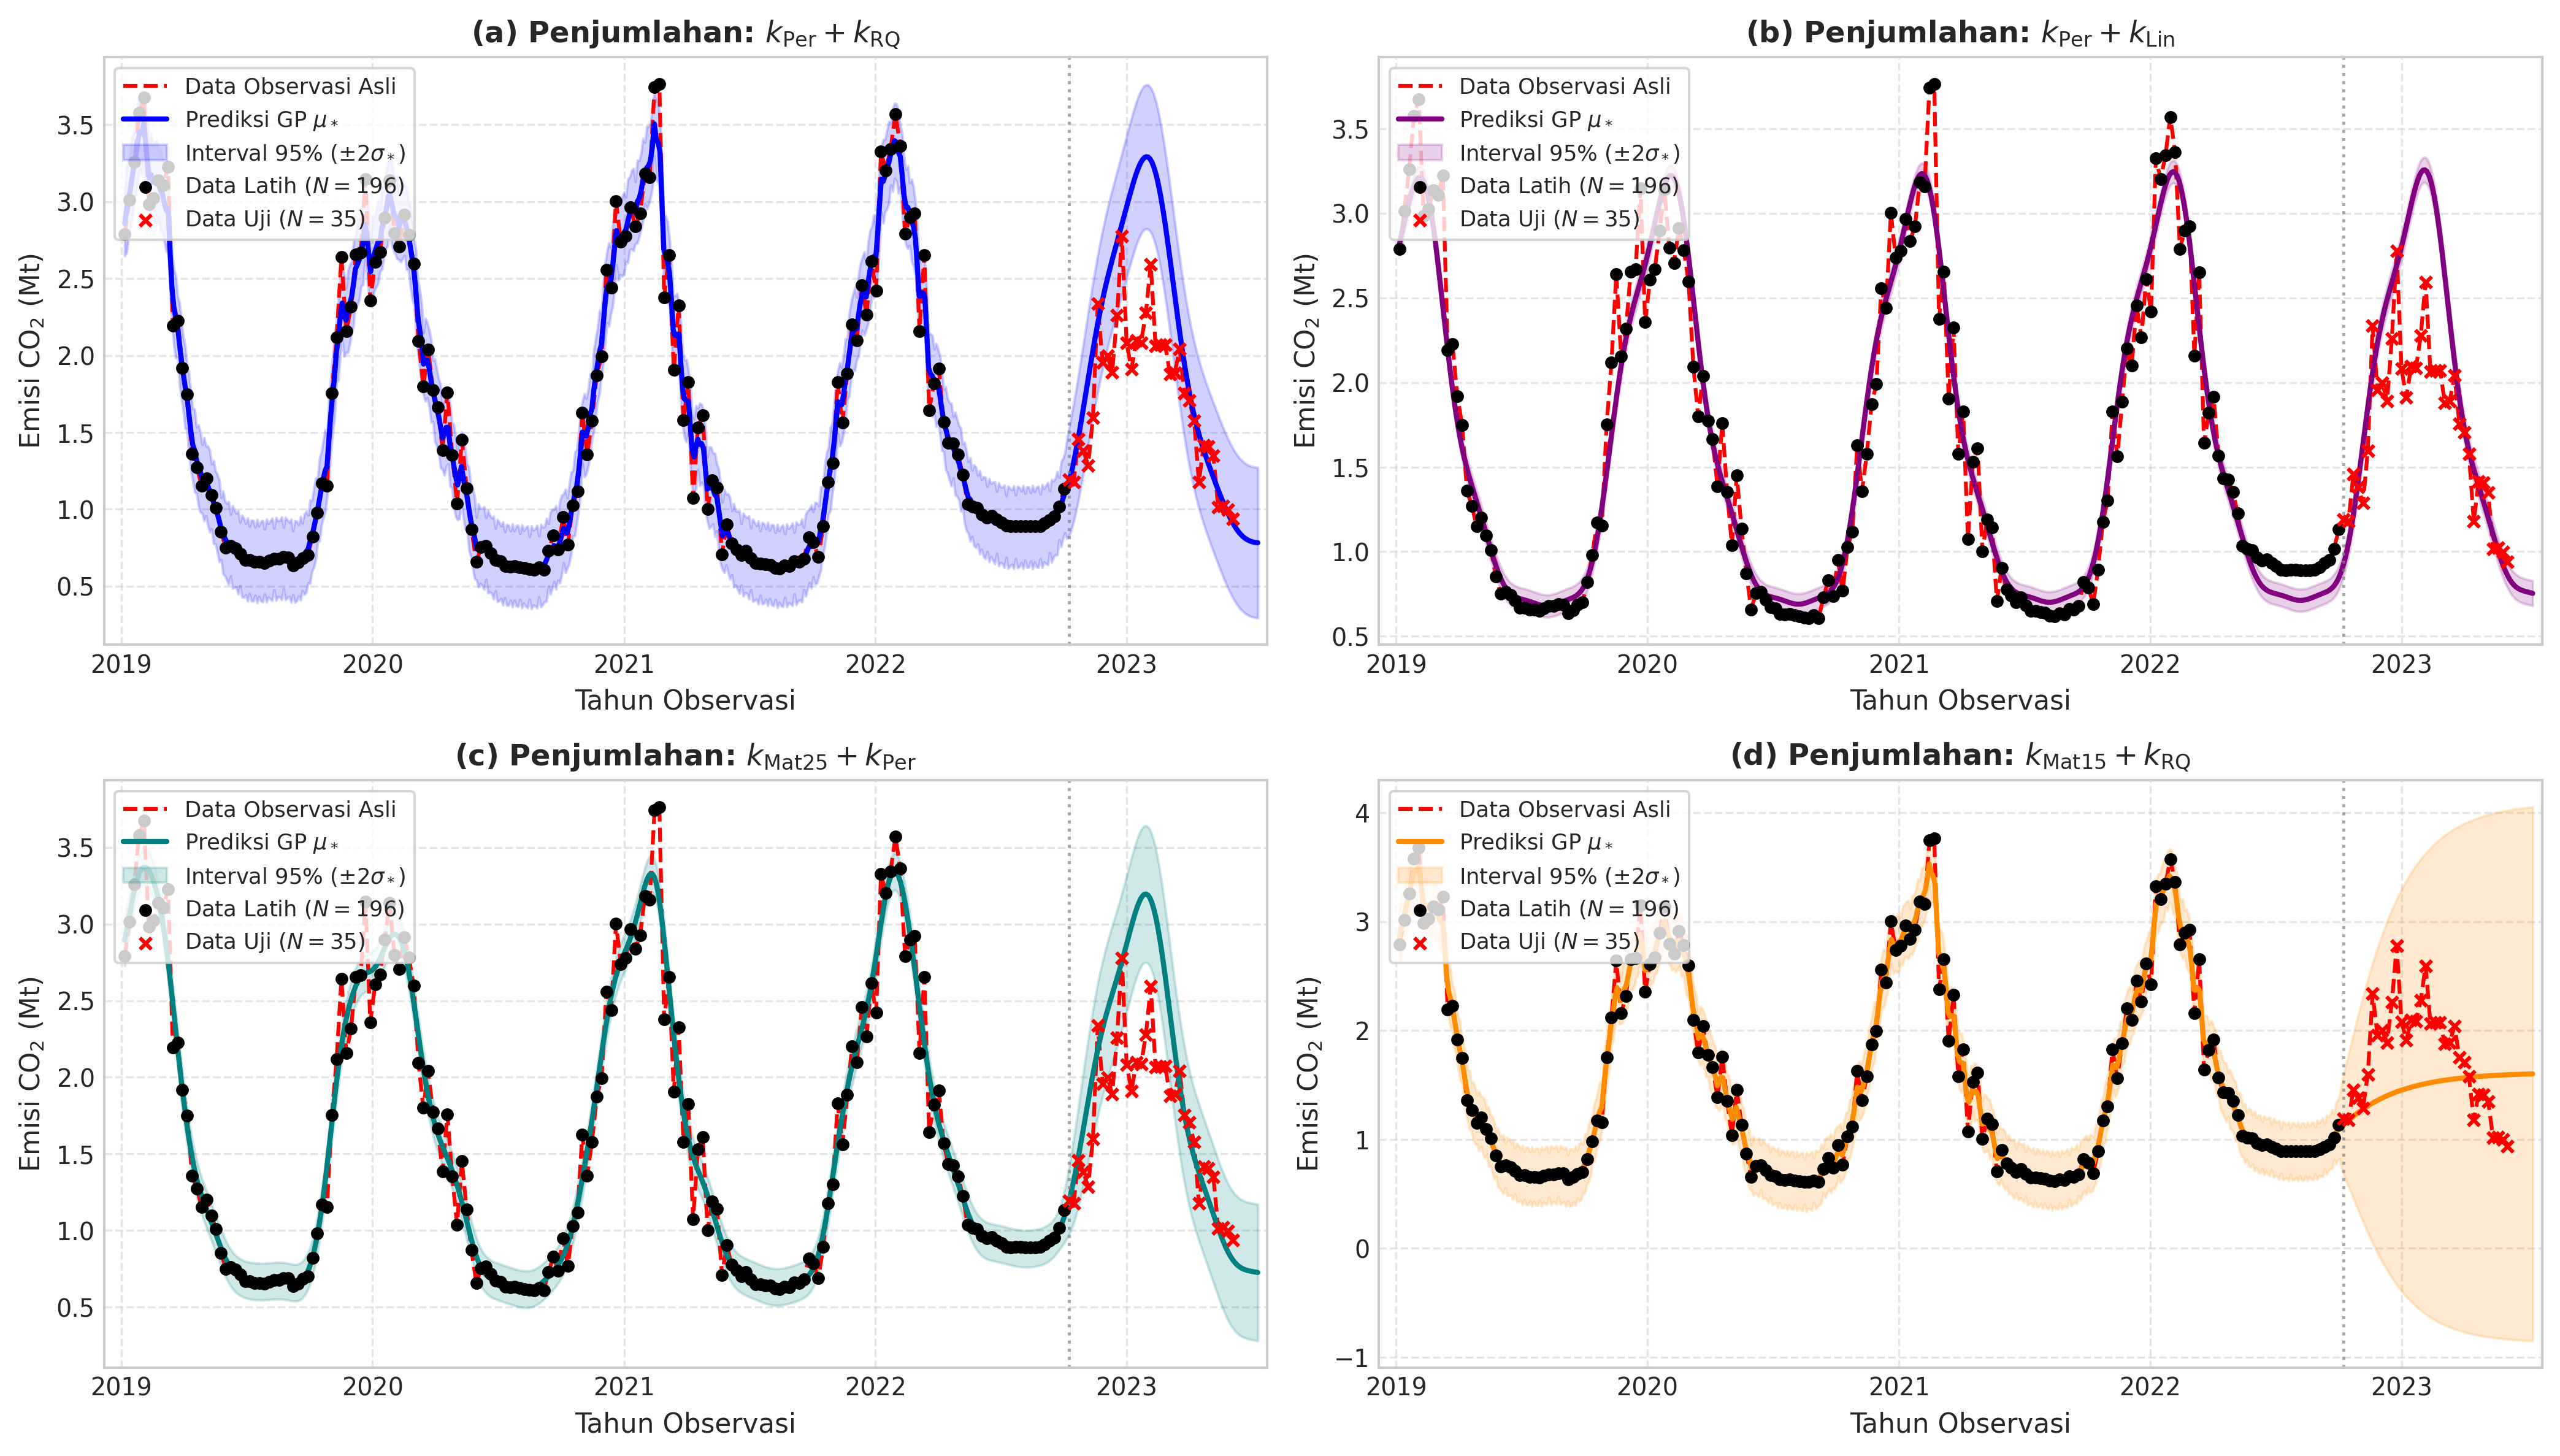

In [8]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import os

# Style persis seperti pada kernel_fitting di Bimbingan 05
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 9.5
plt.rcParams['axes.labelsize'] = 10.5
plt.rcParams['axes.titlesize'] = 11.5
plt.rcParams['legend.fontsize'] = 8.5

# Grid waktu kontinyu untuk kurva prediksi dan pita ketidakpastian
X_dense = np.linspace(X.min(), X.max() + 0.1, 600).reshape(-1, 1)
dense_dates = [t0 + pd.Timedelta(days=float(t * 365.25)) for t in X_dense.flatten()]

fig, axes = plt.subplots(2, 2, figsize=(14, 8), dpi=300)

configs = [
    {
        'title': r'(a) Penjumlahan: $k_{\mathrm{Per}} + k_{\mathrm{RQ}}$',
        'color': 'blue',
        'color_line': 'b-'
    },
    {
        'title': r'(b) Penjumlahan: $k_{\mathrm{Per}} + k_{\mathrm{Lin}}$',
        'color': 'purple',
        'color_line': 'purple'
    },
    {
        'title': r'(c) Penjumlahan: $k_{\mathrm{Mat25}} + k_{\mathrm{Per}}$',
        'color': 'teal',
        'color_line': 'teal'
    },
    {
        'title': r'(d) Penjumlahan: $k_{\mathrm{Mat15}} + k_{\mathrm{RQ}}$',
        'color': 'darkorange',
        'color_line': 'darkorange'
    }
]

dates_train = df_weekly['date'].iloc[:n_train]
dates_test = df_weekly['date'].iloc[n_train:]

for idx, (name, gp) in enumerate(models.items()):
    row = idx // 2
    col = idx % 2
    ax = axes[row, col]
    cfg = configs[idx]
    
    # Prediksi posterior GP: mean dan standar deviasi
    y_mean, y_std = gp.predict(X_dense, return_std=True)
    
    # 1. Garis Data Observasi Asli (True trajectory)
    ax.plot(df_weekly['date'], df_weekly['value'], 'r--', lw=1.5, label='Data Observasi Asli')
    
    # 2. Kurva Prediksi GP mu_*
    ax.plot(dense_dates, y_mean, cfg['color_line'], lw=2, label=r'Prediksi GP $\mu_*$')
    
    # 3. Interval Keyakinan 95% (mu +- 2 sigma)
    ax.fill_between(
        dense_dates, y_mean - 2 * y_std, y_mean + 2 * y_std,
        color=cfg['color'], alpha=0.18, label=r'Interval $95\%$ ($\pm 2\sigma_*$)'
    )
    
    # 4. Scatter Data Latih (Train)
    ax.scatter(dates_train, y_train, c='black', s=16, zorder=5, label=f'Data Latih ($N={n_train}$)')
    
    # 5. Scatter Data Uji (Test)
    ax.scatter(dates_test, y_test, c='red', marker='x', s=20, zorder=5, label=f'Data Uji ($N={len(y_test)}$)')
    
    # Batas Train-Test
    ax.axvline(split_date, color='gray', linestyle=':', lw=1.2, alpha=0.7)
    
    # Formatting judul dan label sumbu
    ax.set_title(cfg['title'], fontweight='bold')
    ax.set_xlabel('Tahun Observasi')
    ax.set_ylabel(r'Emisi $\mathrm{CO}_2$ (Mt)')
    ax.legend(loc='upper left', frameon=True)
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    ax.set_xlim(df_weekly['date'].min() - pd.Timedelta(days=30), df_weekly['date'].max() + pd.Timedelta(days=50))

plt.tight_layout()

# Simpan figur resolusi tinggi ke direktori figures
fig_dir = "figures"
os.makedirs(fig_dir, exist_ok=True)
plt.savefig(os.path.join(fig_dir, "kernel_fitting_co2.pdf"), bbox_inches='tight')
plt.savefig(os.path.join(fig_dir, "kernel_fitting_co2.png"), bbox_inches='tight')
plt.show()



### 🧠 Analisis & Evaluasi Komparatif Kinerja 4 Kombinasi Kernel:

1. **Peran Kunci Kernel Periodik (`ExpSineSquared`)**:
   * **Kombinasi 1, 2, dan 3** yang memuat kernel `ExpSineSquared` berhasil merekonstruksi dan meneruskan osilasi musiman tahunan ke wilayah data uji (ekstrapolasi) dengan sangat konsisten.
   * **Kombinasi 1 (ExpSineSquared + RationalQuadratic)** menghasilkan *fitting* data latih paling presisi (Train MSE terendah $\approx 0.0075$ dan nilai Log Marginal Likelihood tertinggi $\text{LML} = -12.76$). Hal ini karena `RationalQuadratic` bertindak sebagai penyerap fluktuasi multi-skala yang sangat fleksibel.

2. **Kegagalan Ekstrapolasi Siklis pada Kombinasi 4 (Tanpa Periodik)**:
   * Pada **Kombinasi 4 (`Matern + RationalQuadratic`)**, kedua kernel bersifat stasioner lokal tanpa komponen trigonometrik.
   * Hasilnya, pada wilayah *training*, kombinasi ini masih mampu mengikuti naik-turun data, namun pada wilayah ekstrapolasi/data uji, **prediksi rata-ratanya langsung meluruh (*decay*) menuju nilai rata-rata konstan** dengan pita ketidakpastian yang melebar.
   * Hal ini memberikan bukti empiris bahwa **kernel periodik mutlak diperlukan** untuk memodelkan proses fisik musiman seperti emisi $\text{CO}_2$ pemukiman.

3. **Kombinasi 2 (ExpSineSquared + DotProduct)**:
   * Penambahan `DotProduct` (linier) memaksakan adanya tren kemiringan global. Namun, karena emisi $\text{CO}_2$ residential di US relatif stabil (tidak mengalami kenaikan atau penurunan linier jangka panjang yang tajam), model ini mendapatkan penalti marginal likelihood terbesar ($\text{LML} = -104.24$).